# OpenSky Flight Trajectories on Vulkan GPU (`vkdata`)

A full Vulkan GPU recreation of the [HoloViz OpenSky Flight Trajectories](https://examples.holoviz.org/gallery/opensky/opensky.html) gallery example using **`vknumpy` + `vkpandas` + `vkspatial` + `vkshader` + `vkholoviews` + `vkpanel`**.

- **10,227,910** real commercial flight trajectory points collected from the OpenSky Network over 4 days.
- Zero-copy Vulkan SPIR-V line-segment rasterization (`line_raster.comp`) for **count**, **mean velocity**, and **categorical RGB** (`origin`, `ascending`) aggregations directly on shared `VkBuffer`s.
- Live interactive pan/zoom with Esri basemaps, 6-city European airport holding-pattern close-ups, and a reactive `vkpanel` explorer.

In [1]:
import sys, time, urllib.request
from pathlib import Path

_root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
import vknumpy as vnp
import vkpandas as vpd
import vkspatial as vksp
import vkshader as vks
import vkholoviews as hv
import vkpanel as pn

data_path = Path.home() / ".cache/vkdata/opensky/opensky.parq"
if not data_path.is_file():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading opensky.parq (~199 MB)...")
    urllib.request.urlretrieve("http://s3.amazonaws.com/datashader-data/opensky.parq", data_path)

t0 = time.perf_counter()
flights = vpd.read_parquet(data_path)
# Pre-cast once on GPU for fastest interactive pan/zoom
flights["longitude"] = flights["longitude"].astype(np.float32)
flights["latitude"]  = flights["latitude"].astype(np.float32)
flights["velocity"]  = flights["velocity"].astype(np.float32)
flights["ascending"] = flights["ascending"].astype(np.int32)
print(f"Loaded {len(flights):,} flight trajectory points into GPU vkpandas in {time.perf_counter() - t0:.2f}s")
flights.head(5)

ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Loaded 10,227,910 flight trajectory points into GPU vkpandas in 3.06s


       longitude   latitude  origin  ascending            velocity
0     -989418.75  4844618.0                  1   57.11000061035156
1   -991110.8125  4850173.5                  1  60.150001525878906
2   -991544.9375  4855093.0                  1   64.83999633789062
3    -991767.625  4860523.5                  1                70.5
4   -995084.9375  4864169.5                  1   78.62999725341797

## 1. All Flight Trajectories (GPU Line Rasterization + Fire Colormap)

All 10.2M NaN-separated flight polyline segments rasterized in a single zero-copy Vulkan SPIR-V `line_raster.comp` pass and shaded with GPU histogram equalization (`eq_hist`).

GPU rasterized & shaded 10.23M flight segments in 40.4 ms


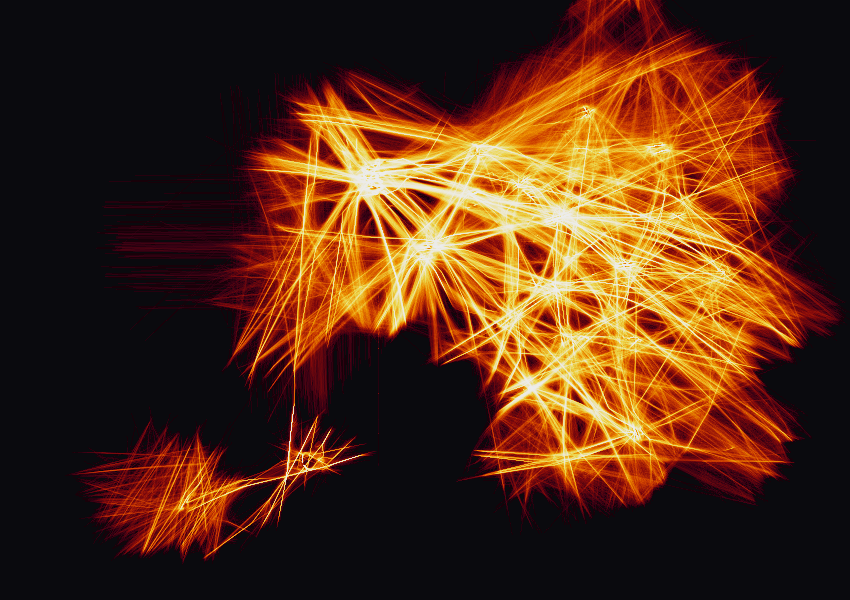

In [2]:
plot_width, plot_height = 850, 600
x_range = (-2.0e6, 2.5e6)
y_range = (4.1e6, 7.8e6)

cvs = vks.Canvas(plot_width, plot_height, x_range=x_range, y_range=y_range)
t0 = time.perf_counter()
agg = cvs.line(flights, "longitude", "latitude", agg="count")
img = vks.shade(agg, how="eq_hist", spread_px=0)
print(f"GPU rasterized & shaded 10.23M flight segments in {(time.perf_counter() - t0)*1000:.1f} ms")
img

## 2. Interactive Flight Trajectories on Esri Basemap (+ Live Linked Velocity Histogram)

Drag to pan, scroll to zoom (try zooming into **London** or **Frankfurt**!), or Shift+drag to box-zoom. Both the trajectory map and the linked velocity histogram recompute directly on the Vulkan GPU.

In [3]:
flight_map = (
    hv.Tiles("esri")
    * hv.datashade(hv.Path(flights, ["longitude", "latitude"]), how="eq_hist", spread_px=0)
).opts(width=680, height=500, xlim=x_range, ylim=y_range, title="OpenSky Flight Density (10.23M)")

vel_hist = hv.Histogram(flights, "velocity", bins=40, range=(0, 300)).opts(
    width=380, height=280, title="Viewport Velocity (m/s)"
)

(flight_map + vel_hist).interact();

## 3. Coloring by Country of Origin, Ascending vs. Descending, and Mean Velocity

- **Origin (`agg='by', column='origin', color_key='hsv_r'`)**: each country gets a distinct HSV hue blended per pixel on GPU.
- **Ascending vs. Descending (`agg='by', column='ascending', color_key=['red', 'blue']`)**: **Red** = descending/landing, **Blue** = ascending/takeoff.
- **Mean Velocity (`agg='mean', column='velocity', cmap='fire_r'`)**: slower approaches near airports stand out against high-speed cruise corridors.

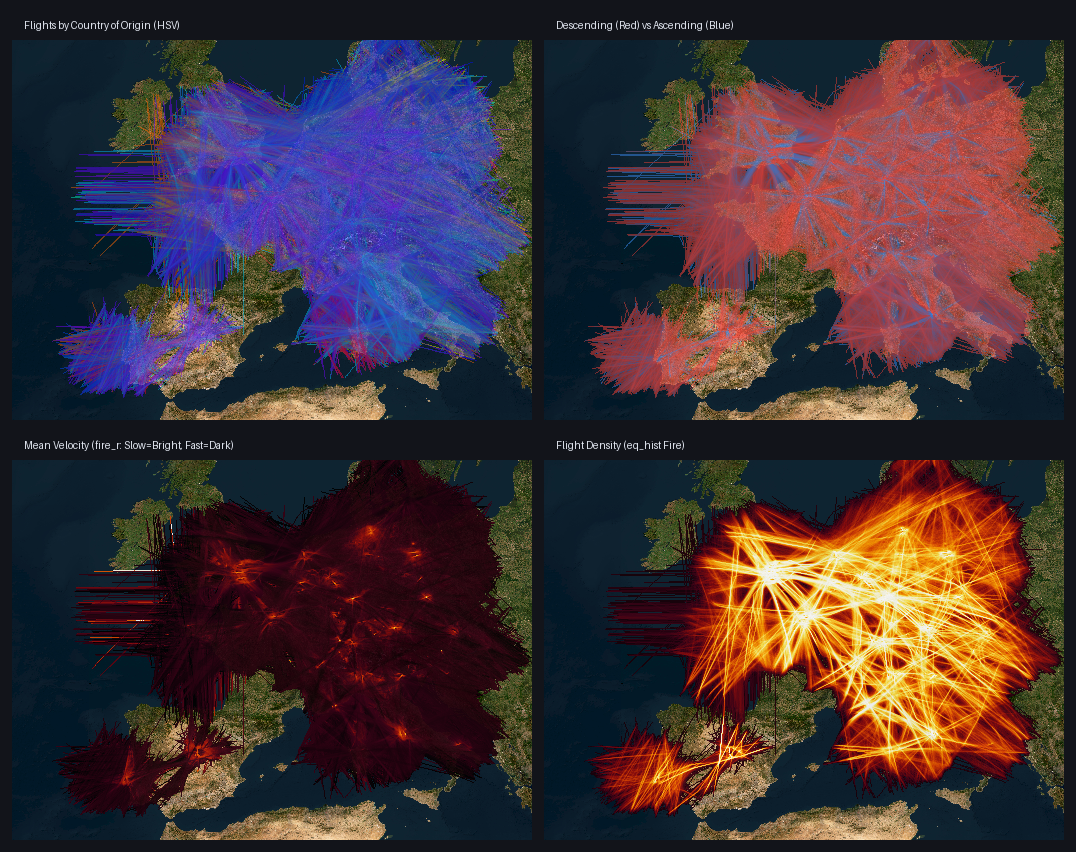

In [4]:
by_origin = (
    hv.Tiles("esri")
    * hv.datashade(hv.Path(flights, ["longitude", "latitude"]), agg="by", column="origin", color_key="hsv_r")
).opts(width=520, height=380, xlim=x_range, ylim=y_range, title="Flights by Country of Origin (HSV)")

by_asc = (
    hv.Tiles("esri")
    * hv.datashade(hv.Path(flights, ["longitude", "latitude"]), agg="by", column="ascending", color_key=["red", "blue"])
).opts(width=520, height=380, xlim=x_range, ylim=y_range, title="Descending (Red) vs Ascending (Blue)")

by_vel = (
    hv.Tiles("esri")
    * hv.datashade(hv.Path(flights, ["longitude", "latitude"]), agg="mean", column="velocity", cmap="fire_r", vmin=0.0, vmax=260.0)
).opts(width=520, height=380, xlim=x_range, ylim=y_range, title="Mean Velocity (fire_r: Slow=Bright, Fast=Dark)")

by_density = (
    hv.Tiles("esri")
    * hv.datashade(hv.Path(flights, ["longitude", "latitude"]), how="eq_hist", spread_px=0)
).opts(width=520, height=380, xlim=x_range, ylim=y_range, title="Flight Density (eq_hist Fire)")

(by_origin + by_asc + by_vel + by_density).cols(2)

## 4. European Airport Close-Ups (Holding Patterns)

Using [`vkspatial.lonlat_to_mercator`] to project 6 major European hubs (`±150 km` window) and rendering a 3-column `vkholoviews.Layout` colored by country of origin, plus a high-res **Zurich** close-up.

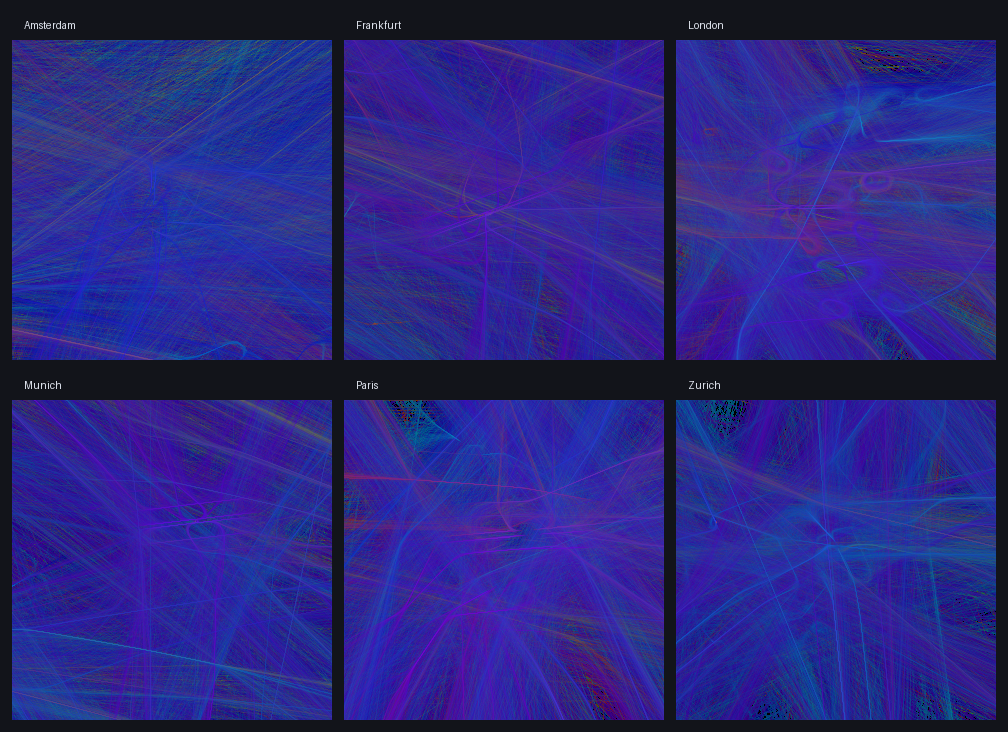

In [5]:
CITIES_LONLAT = {
    "Frankfurt": (8.6821, 50.1109),
    "London":    (-0.1278, 51.5074),
    "Paris":     (2.3522, 48.8566),
    "Amsterdam": (4.8952, 52.3702),
    "Zurich":    (8.5417, 47.3769),
    "Munich":    (11.5820, 48.1351),
}

radius_m = 150_000.0
city_ranges = {}
for city, (lon, lat) in CITIES_LONLAT.items():
    mx, my = vksp.lonlat_to_mercator(np.array([lon], dtype=np.float32), np.array([lat], dtype=np.float32))
    cx, cy = float(mx.to_numpy()[0]), float(my.to_numpy()[0])
    city_ranges[city] = dict(xlim=(cx - radius_m, cx + radius_m), ylim=(cy - radius_m, cy + radius_m))

city_plots = [
    hv.datashade(
        hv.Path(flights, ["longitude", "latitude"]),
        agg="by", column="origin", color_key="hsv_r",
    ).opts(width=320, height=320, title=city, **ranges)
    for city, ranges in sorted(city_ranges.items())
]

hv.Layout(city_plots).cols(3)

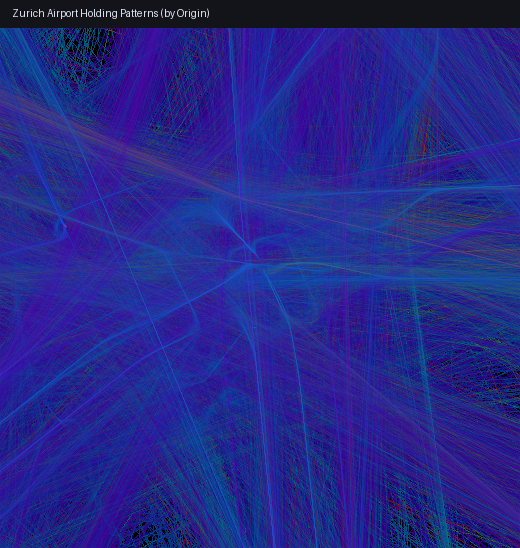

In [6]:
# High-res Zurich holding-pattern close-up
hv.datashade(
    hv.Path(flights, ["longitude", "latitude"]),
    agg="by", column="origin", color_key="hsv_r",
).opts(width=520, height=520, title="Zurich Airport Holding Patterns (by Origin)", **city_ranges["Zurich"])

## 5. Interactive `vkpanel` Airspace Explorer

Switch between **Europe** and any of the **6 airport hubs**, toggle the **Esri basemap**, and switch GPU shader modes (**Density**, **Origin**, **Ascending/Descending**, **Mean Velocity**) live!

In [7]:
region_dd = pn.Select(name="Region", options=["Europe"] + sorted(city_ranges.keys()), value="London")
mode_dd = pn.Select(
    name="Mode",
    options=["Ascending vs Descending", "Country of Origin", "Flight Density (Fire)", "Mean Velocity (fire_r)"],
    value="Ascending vs Descending",
)
tiles_cb = pn.Checkbox(name="Esri Basemap", value=True)

def _render_airspace(region, mode, show_tiles):
    if region == "Europe":
        xr, yr, w, h = x_range, y_range, 720, 520
    else:
        xr, yr, w, h = city_ranges[region]["xlim"], city_ranges[region]["ylim"], 560, 560
    path = hv.Path(flights, ["longitude", "latitude"])
    if mode == "Ascending vs Descending":
        ds = hv.datashade(path, agg="by", column="ascending", color_key=["red", "blue"])
    elif mode == "Country of Origin":
        ds = hv.datashade(path, agg="by", column="origin", color_key="hsv_r")
    elif mode == "Mean Velocity (fire_r)":
        ds = hv.datashade(path, agg="mean", column="velocity", cmap="fire_r", vmin=0.0, vmax=260.0)
    else:
        ds = hv.datashade(path, how="eq_hist", spread_px=0)
    elem = (hv.Tiles("esri") * ds) if show_tiles else ds
    return elem.opts(width=w, height=h, xlim=xr, ylim=yr, title=f"{region} — {mode}")

pn.Card(
    pn.Row(region_dd, mode_dd, tiles_cb),
    pn.bind(_render_airspace, region_dd, mode_dd, tiles_cb),
    title="OpenSky Vulkan GPU Airspace Explorer",
)